In [1]:
import pandas as pd
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

In [2]:
df = pd.read_csv("https://autogluon.s3.amazonaws.com/datasets/timeseries/m4_hourly_subset/train.csv")
df.head()

,item_id,timestamp,target
0,H1,1750-01-01 00:00:00,605.0
1,H1,1750-01-01 01:00:00,586.0
2,H1,1750-01-01 02:00:00,586.0
3,H1,1750-01-01 03:00:00,559.0
4,H1,1750-01-01 04:00:00,511.0


In [3]:
train_data = TimeSeriesDataFrame.from_data_frame(
    df,
    id_column="item_id",
    timestamp_column="timestamp"
)
train_data.head()

target
item_id timestamp                  
H1      1750-01-01 00:00:00   605.0
        1750-01-01 01:00:00   586.0
        1750-01-01 02:00:00   586.0
        1750-01-01 03:00:00   559.0
        1750-01-01 04:00:00   511.0

In [4]:
predictor = TimeSeriesPredictor(
    prediction_length=48,
    path="autogluon-m4-hourly",
    target="target",
    eval_metric="MASE",
)

predictor.fit(
    train_data,
    presets="medium_quality",
    time_limit=600,
)

Beginning AutoGluon training... Time limit = 600s
AutoGluon will save models to 'c:\Users\NishigandhaChoudhury\OneDrive\Desktop\AutoML\AUTOGLUON\TIME-SERIES\autogluon-m4-hourly'
=================== System Info ===================
AutoGluon Version:  1.6.1
Python Version:     3.13.1
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26200
CPU Count:          16
Pytorch Version:    2.13.0+cpu
CUDA Version:       CUDA is not available
GPU Memory:         
Total GPU Memory:   Free: 0.00 GB, Allocated: 0.00 GB, Total: 0.00 GB
GPU Count:          0
Memory Avail:       1.83 GB / 15.40 GB (11.9%)
Disk Space Avail:   2.83 GB / 105.30 GB (2.7%)
	We recommend a minimum available disk space of 10 GB, and large datasets may require more.
Setting presets to: medium_quality

Fitting with arguments:
{'enable_ensemble': True,
 'eval_metric': MASE,
 'hyperparameters': 'light',
 'known_covariates_names': [],
 'num_val_windows': 1,
 'prediction_length': 48,
 'quantile_levels': 

In [5]:
predictions = predictor.predict(train_data)
predictions.head()

Model not specified in predict, will default to the model with the best validation score: WeightedEnsemble


Loading weights: 100%|██████████| 92/92 [00:00<00:00, 2629.07it/s]


mean         0.1         0.2         0.3  \
item_id timestamp                                                             
H1      1750-01-30 04:00:00  624.151338  605.967414  612.493887  616.520312   
        1750-01-30 05:00:00  563.155070  539.766098  548.362082  554.076454   
        1750-01-30 06:00:00  519.092172  491.170383  501.600654  508.258439   
        1750-01-30 07:00:00  487.981452  456.249097  467.701423  475.535863   
        1750-01-30 08:00:00  466.565566  430.830742  443.513286  452.361614   

                                    0.4         0.5         0.6         0.7  \
item_id timestamp                                                             
H1      1750-01-30 04:00:00  620.318914  624.151338  628.194000  632.438396   
        1750-01-30 05:00:00  558.766981  563.155070  567.716160  572.842657   
        1750-01-30 06:00:00  513.784326  519.092172  524.509428  530.127012   
        1750-01-30 07:00:00  481.730717  487.981452  494.179071  500.656951   
        1750-01-30 08:00:00  459.331661  466.565566  473.899562  481.417415   

                                    0.8         0.9  
item_id timestamp                                    
H1      1750-01-30 04:00:00  637.138871  644.563257  
        1750-01-30 05:00:00  579.054774  588.274406  
        1750-01-30 06:00:00  537.086970  547.232067  
        1750-01-30 07:00:00  508.027029  518.755332  
        1750-01-30 08:00:00  489.820189  501.421489

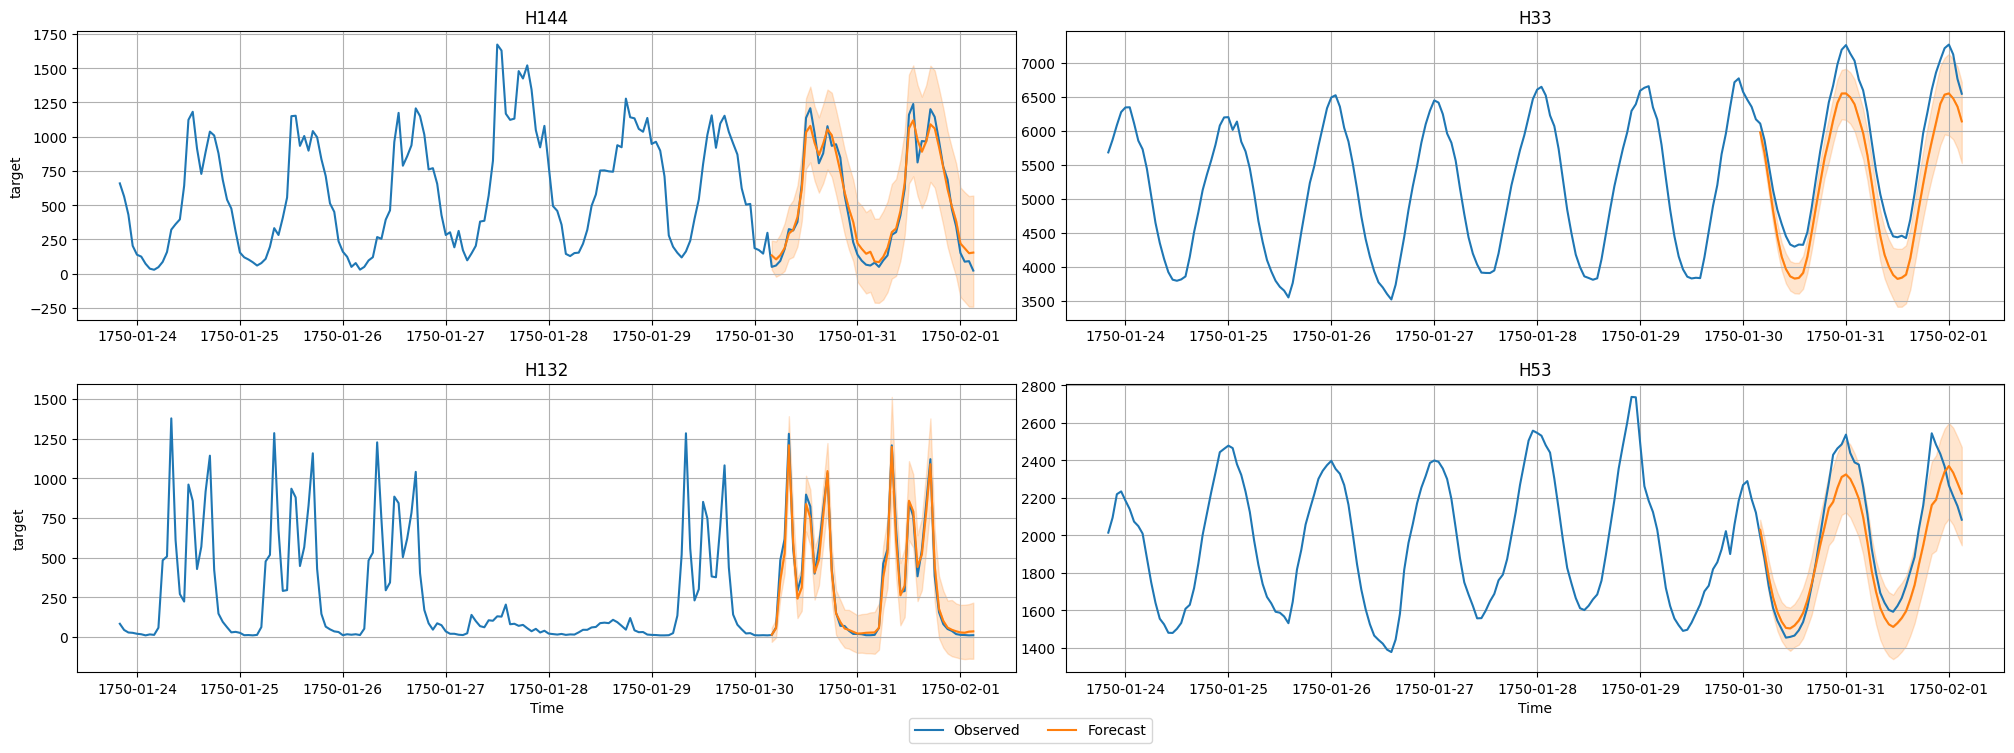

In [6]:
import matplotlib.pyplot as plt

# TimeSeriesDataFrame can also be loaded directly from a file
test_data = TimeSeriesDataFrame.from_path("https://autogluon.s3.amazonaws.com/datasets/timeseries/m4_hourly_subset/test.csv")

# Plot 4 randomly chosen time series and the respective forecasts
predictor.plot(test_data, predictions, quantile_levels=[0.1, 0.9], max_history_length=200, max_num_item_ids=4);

In [7]:
# The test score is computed using the last
# prediction_length=48 timesteps of each time series in test_data
predictor.leaderboard(test_data)

Additional data provided, testing on additional data. Resulting leaderboard will be sorted according to test score (`score_test`).


Loading weights: 100%|██████████| 92/92 [00:00<00:00, 1205.02it/s]


,model,score_test,score_val,pred_time_test,pred_time_val,fit_time_marginal,fit_order
0,WeightedEnsemble,-0.740068,-0.820306,46.574827,58.138193,1.381120,8
1,Chronos2,-0.765236,-0.877750,7.153711,6.713918,29.029340,6
2,RecursiveTabular,-0.862797,-0.933874,0.938965,0.970934,16.440107,2
3,Toto2,-0.890937,-0.901884,1.944793,0.961730,1.068671,7
4,SeasonalNaive,-1.022854,-1.216909,0.370943,9.361287,0.150894,1
5,DirectTabular,-1.648202,-1.372871,1.055173,0.915628,7.211273,3
6,ETS,-1.806128,-1.965912,32.928609,37.327465,0.147207,4
7,Theta,-1.905367,-2.142551,2.108773,1.855501,0.121078,5
